<a href="https://colab.research.google.com/github/LepingWan/ECE247A/blob/main/HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1

**(a)** Let $r_i=y^{(i)}-(x^{(i)})^T\theta$. Then
$$
\left(y^{(i)}-(x^{(i)}+\delta^{(i)})^T\theta\right)^2
=r_i^2-2r_i(\delta^{(i)})^T\theta+\theta^T\delta^{(i)}(\delta^{(i)})^T\theta.
$$
Since $E[\delta^{(i)}]=0$ and $E[\delta^{(i)}(\delta^{(i)})^T]=\sigma^2 I$,
$$
E\left[\left(y^{(i)}-(x^{(i)}+\delta^{(i)})^T\theta\right)^2\right]
=r_i^2+\sigma^2\theta^T\theta.
$$
Averaging over the $N$ examples gives
$$
E[\widetilde L(\theta)]
=\frac{1}{N}\sum_{i=1}^N r_i^2+\sigma^2\theta^T\theta
=L(\theta)+\sigma^2\|\theta\|_2^2.
$$
So $R=\sigma^2\|\theta\|_2^2$, which does not depend on $D$.

**(b)** This adds L2 regularization with coefficient $\sigma^2$. Large weights get a larger penalty, so minimizing the expected loss favors smaller weights.

**(c)** As $\sigma\to0$, the penalty goes to zero. The expected loss becomes the original least-squares loss, with no noise regularization.

**(d)** As $\sigma\to\infty$, the penalty forces the minimizing weights toward zero. To see this, if $\theta_\sigma$ minimizes the expected loss,
$$
\sigma^2\|\theta_\sigma\|_2^2
\le L(\theta_\sigma)+\sigma^2\|\theta_\sigma\|_2^2
\le L(0)=\frac{1}{N}\sum_{i=1}^N (y^{(i)})^2.
$$
Hence $\|\theta_\sigma\|_2\to0$. The predictions $(x^{(i)})^T\theta_\sigma$ go to zero, so the model underfits.

# Problem 2

## This is the k-nearest neighbors workbook for ECE C147/C247 Assignment #2

Please follow the notebook linearly to implement k-nearest neighbors.

Please print out the workbook entirely when completed.

The goal of this workbook is to give you experience with the data, training and evaluating a simple classifier, k-fold cross validation, and as a Python refresher.

## Import the appropriate libraries

In [1]:
from pathlib import Path
import sys
import urllib.request
import tarfile
import hashlib
import os

repo_dir = Path.cwd()
if not (repo_dir / 'nndl' / 'knn.py').exists():
    repo_dir = Path('/content/ECE247A')
    repo_dir.mkdir(parents=True, exist_ok=True)
    base_url = 'https://raw.githubusercontent.com/LepingWan/ECE247A/main/'
    for filename in ['nndl/__init__.py', 'nndl/knn.py', 'utils/__init__.py', 'utils/data_utils.py']:
        target = repo_dir / filename
        target.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(base_url + filename, target)
sys.path.insert(0, str(repo_dir))

data_dir = Path(os.environ.get('CIFAR10_DIR', str(repo_dir / 'cifar-10-batches-py')))
if not (data_dir / 'test_batch').exists():
    archive = repo_dir / 'cifar-10-python.tar.gz'
    if not archive.exists():
        urllib.request.urlretrieve('https://cseweb.ucsd.edu/~weijian/static/datasets/cifar/cifar-10-python.tar.gz', archive)
    with open(archive, 'rb') as f:
        checksum = hashlib.file_digest(f, 'md5').hexdigest()
    if checksum != 'c58f30108f718f92721af3b95e74349a':
        raise ValueError('CIFAR-10 download is incomplete; delete the archive and rerun.')
    with tarfile.open(archive, 'r:gz') as f:
        f.extractall(path=repo_dir, filter='data')
    data_dir = repo_dir / 'cifar-10-batches-py'
print('CIFAR-10 folder:', data_dir)

CIFAR-10 folder: /tmp/cifar-10-batches-py


In [2]:
import numpy as np # for doing most of our calculations
import matplotlib.pyplot as plt# for plotting
from utils.data_utils import load_CIFAR10 # function to load the CIFAR-10 dataset.

# Load matplotlib images inline
%matplotlib inline

# These are important for reloading any code you write in external .py files.
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

In [3]:
cifar10_dir = str(data_dir)
X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


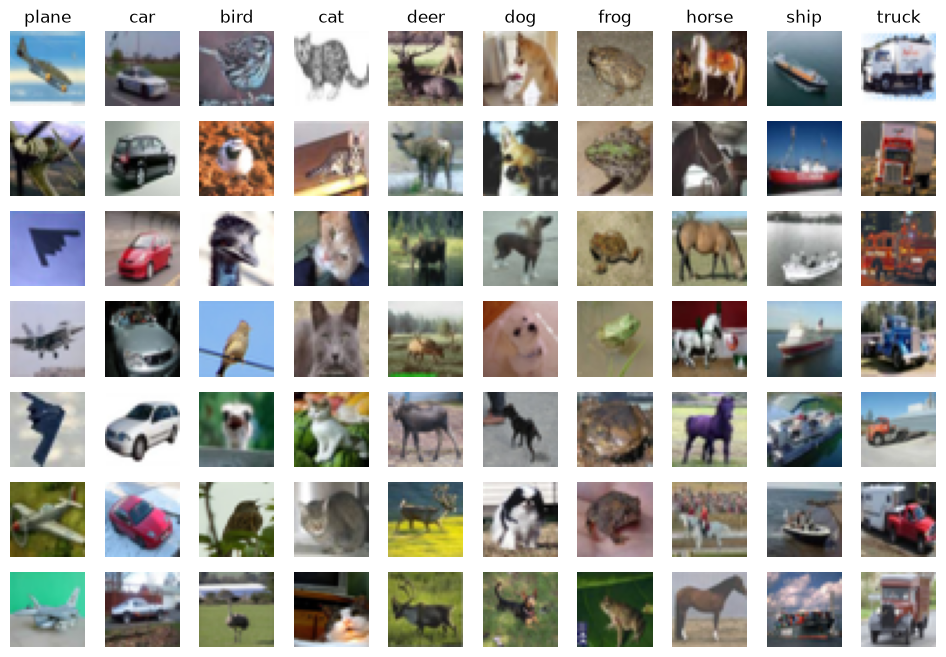

In [4]:
np.random.seed(0)
plt.figure(figsize=(12, 8))
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [5]:
# Subsample the data for more efficient code execution in this exercise
num_training = 5000
mask = list(range(num_training))
X_train = X_train[mask]
y_train = y_train[mask]

num_test = 500
mask = list(range(num_test))
X_test = X_test[mask]
y_test = y_test[mask]

# Reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
print(X_train.shape, X_test.shape)

(5000, 3072) (500, 3072)


# K-nearest neighbors

In the following cells, you will build a KNN classifier and choose hyperparameters via k-fold cross-validation.

In [6]:
# Import the KNN class

from nndl import KNN

In [7]:
# Declare an instance of the knn class.
knn = KNN()

# Train the classifier.
#   We have implemented the training of the KNN classifier.
#   Look at the train function in the KNN class to see what this does.
knn.train(X=X_train, y=y_train)

## Questions

(1) Describe what is going on in the function knn.train().

(2) What are the pros and cons of this training step?

## Answers

(1) `knn.train()` stores the training images and their labels in `self.X_train` and `self.y_train`. It does not fit weights or minimize a loss.

(2) Training is simple and fast since it just stores the data. The downside is that we have to keep the whole training set in memory and compute distances to it when making predictions. With many features, distances can also become less useful (the curse of dimensionality).

## KNN prediction

In the following sections, you will implement the functions to calculate the distances of test points to training points, and from this information, predict the class of the KNN.

In [8]:
# Implement the function compute_distances() in the KNN class.
# Do not worry about the input 'norm' for now; use the default definition of the norm
# in the code, which is the 2-norm.
# You should only have to fill out the clearly marked sections.

import time
time_start =time.time()

dists_L2 = knn.compute_distances(X=X_test)

print('Time to run code: {}'.format(time.time()-time_start))
print('Frobenius norm of L2 distances: {}'.format(np.linalg.norm(dists_L2, 'fro')))

Time to run code: 10.31001329421997
Frobenius norm of L2 distances: 7906696.077040902


#### Really slow code

Note: 
This probably took a while. This is because we use two for loops.  We could increase the speed via vectorization, removing the for loops.

If you implemented this correctly, evaluating np.linalg.norm(dists_L2, 'fro') should return: ~7906696

### KNN vectorization

The above code took far too long to run.  If we wanted to optimize hyperparameters, it would be time-expensive.  Thus, we will speed up the code by vectorizing it, removing the for loops.

I used $\|x-z\|_2^2=\|x\|_2^2+\|z\|_2^2-2x^Tz$. Broadcasting adds the squared norms for every test-training pair, and `X.dot(self.X_train.T)` computes all the inner products. Then I take the square root.

In [9]:
# Implement the function compute_L2_distances_vectorized() in the KNN class.
# In this function, you ought to achieve the same L2 distance but WITHOUT any for loops.
# Note, this is SPECIFIC for the L2 norm.

time_start =time.time()
dists_L2_vectorized = knn.compute_L2_distances_vectorized(X=X_test)
print('Time to run code: {}'.format(time.time()-time_start))
print('Difference in L2 distances between your KNN implementations (should be 0): {}'.format(np.linalg.norm(dists_L2 - dists_L2_vectorized, 'fro')))

Time to run code: 0.09270405769348145
Difference in L2 distances between your KNN implementations (should be 0): 0.0


#### Speedup

Depending on your computer speed, you should see a 10-100x speed up from vectorization.  On our computer, the vectorized form took 0.36 seconds while the naive implementation took 38.3 seconds. 

### Implementing the prediction

Now that we have functions to calculate the distances from a test point to given training points, we now implement the function that will predict the test point labels.

In [10]:
# Evaluate k=1 on the test data.
y_pred = knn.predict_labels(dists_L2_vectorized, k=1)
baseline_error = np.mean(y_pred != y_test)
error = baseline_error
print(error)

0.726


If you implemented this correctly, the error should be: 0.726.

This means that the k-nearest neighbors classifier is right 27.4% of the time, which is not great, considering that chance levels are 10%.

# Optimizing KNN hyperparameters

In this section, we'll take the KNN classifier that you have constructed and perform cross-validation to choose a best value of $k$, as well as a best choice of norm.

### Create training and validation folds

First, we will create the training and validation folds for use in k-fold cross validation.

In [11]:
num_folds = 5
X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

### Optimizing the number of nearest neighbors hyperparameter.

In this section, we select different numbers of nearest neighbors and assess which one has the lowest k-fold cross validation error.

k =  1: CV error = 0.7344
k =  2: CV error = 0.7626
k =  3: CV error = 0.7504
k =  5: CV error = 0.7268
k =  7: CV error = 0.7256
k = 10: CV error = 0.7198
k = 15: CV error = 0.7250
k = 20: CV error = 0.7210
k = 25: CV error = 0.7242
k = 30: CV error = 0.7266


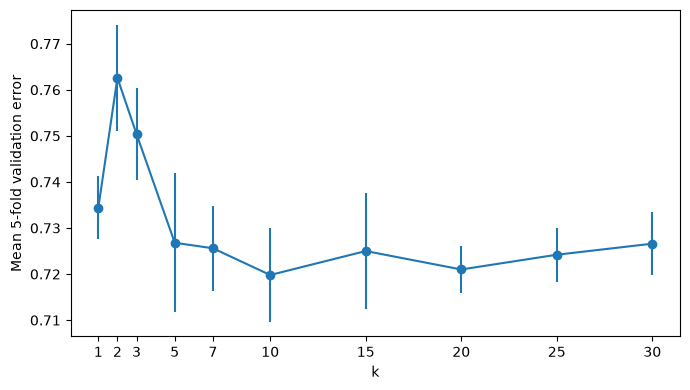

Best k: 10, CV error: 0.7198
Computation time: 10.85


In [12]:
time_start = time.time()
ks = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30]
k_to_errors = {k: [] for k in ks}

for fold in range(num_folds):
    X_val = X_train_folds[fold]
    y_val = y_train_folds[fold]
    X_fit = np.concatenate([X_train_folds[j] for j in range(num_folds) if j != fold])
    y_fit = np.concatenate([y_train_folds[j] for j in range(num_folds) if j != fold])
    fold_knn = KNN()
    fold_knn.train(X_fit, y_fit)
    fold_dists = fold_knn.compute_L2_distances_vectorized(X_val)
    for k in ks:
        y_pred = fold_knn.predict_labels(fold_dists, k=k)
        k_to_errors[k].append(np.mean(y_pred != y_val))

mean_k_errors = np.array([np.mean(k_to_errors[k]) for k in ks])
best_k = ks[np.argmin(mean_k_errors)]
best_k_error = np.min(mean_k_errors)
for k, mean_error in zip(ks, mean_k_errors):
    print('k = %2d: CV error = %.4f' % (k, mean_error))
plt.figure(figsize=(7, 4))
plt.errorbar(ks, mean_k_errors, yerr=[np.std(k_to_errors[k]) for k in ks], fmt='o-')
plt.xlabel('k')
plt.ylabel('Mean 5-fold validation error')
plt.xticks(ks)
plt.tight_layout()
plt.show()
print('Best k: %d, CV error: %.4f' % (best_k, best_k_error))
print('Computation time: %.2f' % (time.time() - time_start))

## Questions:

(1) What value of $k$ is best amongst the tested $k$'s?

(2) What is the cross-validation error for this value of $k$?

## Answers:

(1) The best value is $k=10$. It has the smallest mean validation error among the tested values.

(2) Its five-fold cross-validation error is $0.7198$ ($71.98\%$).

### Optimizing the norm

Next, we test three different norms (the 1, 2, and infinity norms) and see which distance metric results in the best cross-validation performance.

L1: CV error = 0.6886
L2: CV error = 0.7198
Linf: CV error = 0.8370


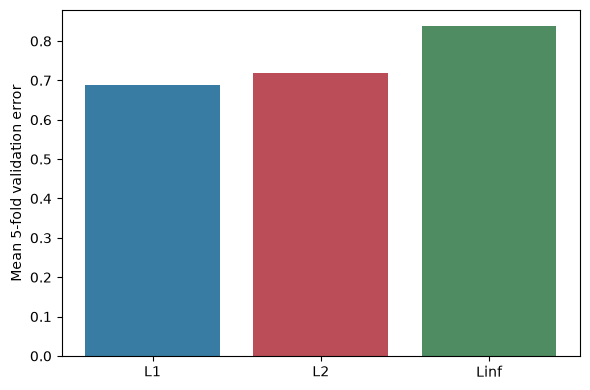

Best norm: L1, k: 10, CV error: 0.6886
Computation time: 58.86


In [13]:
time_start = time.time()
L1_norm = lambda x: np.linalg.norm(x, ord=1)
L2_norm = lambda x: np.linalg.norm(x, ord=2)
Linf_norm = lambda x: np.linalg.norm(x, ord=np.inf)
norms = [L1_norm, L2_norm, Linf_norm]
norm_names = ['L1', 'L2', 'Linf']

# cdist computes the same L1 and Linf distances without slow Python loops.
from scipy.spatial.distance import cdist

def distances_for_norm(model, X, norm_index):
    if norm_index == 1:
        return model.compute_L2_distances_vectorized(X)
    metric = 'cityblock' if norm_index == 0 else 'chebyshev'
    return cdist(X, model.X_train, metric=metric)

norm_to_errors = {name: [] for name in norm_names}
for fold in range(num_folds):
    X_val = X_train_folds[fold]
    y_val = y_train_folds[fold]
    X_fit = np.concatenate([X_train_folds[j] for j in range(num_folds) if j != fold])
    y_fit = np.concatenate([y_train_folds[j] for j in range(num_folds) if j != fold])
    fold_knn = KNN()
    fold_knn.train(X_fit, y_fit)
    for norm_index, name in enumerate(norm_names):
        fold_dists = distances_for_norm(fold_knn, X_val, norm_index)
        y_pred = fold_knn.predict_labels(fold_dists, k=best_k)
        norm_to_errors[name].append(np.mean(y_pred != y_val))

mean_norm_errors = np.array([np.mean(norm_to_errors[name]) for name in norm_names])
best_norm_index = int(np.argmin(mean_norm_errors))
best_norm_name = norm_names[best_norm_index]
best_norm_error = mean_norm_errors[best_norm_index]
for name, mean_error in zip(norm_names, mean_norm_errors):
    print('%s: CV error = %.4f' % (name, mean_error))
plt.figure(figsize=(6, 4))
plt.bar(norm_names, mean_norm_errors, color=['#387ca3', '#ba4d57', '#4f8c62'])
plt.ylabel('Mean 5-fold validation error')
plt.tight_layout()
plt.show()
print('Best norm: %s, k: %d, CV error: %.4f' % (best_norm_name, best_k, best_norm_error))
print('Computation time: %.2f' % (time.time() - time_start))

## Questions:

(1) What norm has the best cross-validation error?

(2) What is the cross-validation error for your given norm and k?

## Answers:

(1) The $L_1$ norm has the lowest mean validation error, using $k=10$ from the previous part.

(2) The five-fold cross-validation error is $0.6886$ ($68.86\%$).

# Evaluating the model on the testing dataset.

Now, given the optimal $k$ and norm you found in earlier parts, evaluate the testing error of the k-nearest neighbors model.

In [14]:
knn.train(X_train, y_train)
test_dists = distances_for_norm(knn, X_test, best_norm_index)
y_pred = knn.predict_labels(test_dists, k=best_k)
error = np.mean(y_pred != y_test)
improvement = baseline_error - error
print('Selected k: %d, norm: %s' % (best_k, best_norm_name))
print('Error rate achieved: %.4f' % error)
print('Baseline error: %.4f' % baseline_error)
print('Error reduction: %.4f (%.2f percentage points)' % (improvement, 100 * improvement))

Selected k: 10, norm: L1
Error rate achieved: 0.7220
Baseline error: 0.7260
Error reduction: 0.0040 (0.40 percentage points)


## Question:

How much did your error improve by cross-validation over naively choosing $k=1$ and using the L2-norm?

## Answer:

The baseline test error is $0.7260$ and the selected model has test error $0.7220$. The reduction is
$$
0.7260-0.7220=0.0040,
$$
so the error improved by $0.40$ percentage points. I chose $k$ and the norm using the training folds, then trained on all 5000 training examples for the final test evaluation.

## knn.py

In [15]:
import inspect
print(inspect.getsource(KNN))

class KNN(object):

  def __init__(self):
    pass

  def train(self, X, y):
    """
    Inputs:
    - X is a numpy array of size (num_examples, D)
    - y is a numpy array of size (num_examples, )
    """
    self.X_train = X
    self.y_train = y

  def compute_distances(self, X, norm=None):
    """
    Compute the distance between each test point in X and each training point
    in self.X_train.

    Inputs:
    - X: A numpy array of shape (num_test, D) containing test data.
    - norm: the function with which the norm is taken.

    Returns:
    - dists: A numpy array of shape (num_test, num_train) where dists[i, j]
      is the Euclidean distance between the ith test point and the jth training
      point.
    """
    if norm is None:
      norm = lambda x: np.sqrt(np.sum(x**2))
      #norm = 2

    num_test = X.shape[0]
    num_train = self.X_train.shape[0]
    dists = np.zeros((num_test, num_train))
    for i in np.arange(num_test):
        
      for j in np.arange(num_train):
 

# Problem 3

Let $\widetilde x^{(j)}=[(x^{(j)})^T,1]^T$ and $\widetilde w_i=[w_i^T,b_i]^T$, so $a_i(x^{(j)})=\widetilde w_i^T\widetilde x^{(j)}$. Assuming independent samples, the likelihood is
$$
\prod_{j=1}^m\Pr(y^{(j)}\mid x^{(j)},\theta).
$$
Taking the log gives
$$
L(\theta)=\sum_{j=1}^m\log\Pr(y^{(j)}\mid x^{(j)},\theta)
=\sum_{j=1}^m\left[\widetilde w_{y^{(j)}}^T\widetilde x^{(j)}
-\log\left(\sum_{k=1}^c e^{\widetilde w_k^T\widetilde x^{(j)}}\right)\right].
$$
For a fixed class $i$,
$$
\nabla_{\widetilde w_i}\left(\widetilde w_{y^{(j)}}^T\widetilde x^{(j)}\right)
=1_{\{i=y^{(j)}\}}\widetilde x^{(j)},
$$
and
$$
\nabla_{\widetilde w_i}\log\left(\sum_{k=1}^c e^{\widetilde w_k^T\widetilde x^{(j)}}\right)
=\frac{e^{\widetilde w_i^T\widetilde x^{(j)}}}{\sum_{k=1}^c e^{\widetilde w_k^T\widetilde x^{(j)}}\widetilde x^{(j)}
=\operatorname{softmax}_i(x^{(j)})\widetilde x^{(j)}.
$$
Thus, for $i=1,\ldots,c$,
$$
\nabla_{\widetilde w_i}L
=\sum_{j=1}^m\left(1_{\{i=y^{(j)}\}}-\operatorname{softmax}_i(x^{(j)})\right)\widetilde x^{(j)}.
$$
Separating the weights and bias,
$$
\nabla_{w_i}L=\sum_{j=1}^m\left(1_{\{i=y^{(j)}\}}-\operatorname{softmax}_i(x^{(j)})\right)x^{(j)},
$$
$$
\nabla_{b_i}L=\sum_{j=1}^m\left(1_{\{i=y^{(j)}\}}-\operatorname{softmax}_i(x^{(j)})\right).
$$

# Problem 4

Let $p_i=y^{(i)}(w^Tx^{(i)}+b)$. For $p_i<1$, the hinge loss is $1-p_i$, so
$$
\nabla_w\operatorname{hinge}_{y^{(i)}}(x^{(i)})=-y^{(i)}x^{(i)},
\qquad
\nabla_b\operatorname{hinge}_{y^{(i)}}(x^{(i)})=-y^{(i)}.
$$
For $p_i>1$, the loss is zero and both derivatives are zero. Averaging over the $K$ samples,
$$
\nabla_w L=-\frac{1}{K}\sum_{i=1}^K y^{(i)}x^{(i)}
1_{\{y^{(i)}(w^Tx^{(i)}+b)<1\}},
$$
$$
\nabla_b L=-\frac{1}{K}\sum_{i=1}^K y^{(i)}
1_{\{y^{(i)}(w^Tx^{(i)}+b)<1\}}.
$$
At $p_i=1$, the hinge is not differentiable. Choosing zero for that sample gives a valid subgradient and matches the strict inequality in these expressions.

# Problem 5

## This is the softmax workbook for ECE C147/C247 Assignment #2

Please follow the notebook linearly to implement a softmax classifier.

Please print out the workbook entirely when completed.

The goal of this workbook is to give you experience with training a softmax classifier.

In [16]:
import random
import numpy as np
from utils.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

np.random.seed(0)
%matplotlib inline

In [17]:
def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000, num_dev=500):
    """
    Load the CIFAR-10 dataset from disk and perform preprocessing to prepare
    it for the linear classifier. These are the same steps as we used for the
    SVM, but condensed to a single function.  
    """
    # Load the raw CIFAR-10 data
    cifar10_dir = str(data_dir)
    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)
    
    # subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]
    mask = np.random.choice(num_training, num_dev, replace=False)
    X_dev = X_train[mask]
    y_dev = y_train[mask]
    
    # Preprocessing: reshape the image data into rows
    X_train = np.reshape(X_train, (X_train.shape[0], -1))
    X_val = np.reshape(X_val, (X_val.shape[0], -1))
    X_test = np.reshape(X_test, (X_test.shape[0], -1))
    X_dev = np.reshape(X_dev, (X_dev.shape[0], -1))
    
    # Normalize the data: subtract the mean image
    mean_image = np.mean(X_train, axis = 0)
    X_train -= mean_image
    X_val -= mean_image
    X_test -= mean_image
    X_dev -= mean_image
    
    # add bias dimension and transform into columns
    X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
    X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
    X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])
    X_dev = np.hstack([X_dev, np.ones((X_dev.shape[0], 1))])
    
    return X_train, y_train, X_val, y_val, X_test, y_test, X_dev, y_dev


# Invoke the above function to get our data.
X_train, y_train, X_val, y_val, X_test, y_test, X_dev, y_dev = get_CIFAR10_data()
print('Train data shape: ', X_train.shape)
print('Train labels shape: ', y_train.shape)
print('Validation data shape: ', X_val.shape)
print('Validation labels shape: ', y_val.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)
print('dev data shape: ', X_dev.shape)
print('dev labels shape: ', y_dev.shape)

Train data shape:  (49000, 3073)
Train labels shape:  (49000,)
Validation data shape:  (1000, 3073)
Validation labels shape:  (1000,)
Test data shape:  (1000, 3073)
Test labels shape:  (1000,)
dev data shape:  (500, 3073)
dev labels shape:  (500,)


## Training a softmax classifier.

The following cells will take you through building a softmax classifier.  You will implement its loss function, then subsequently train it with gradient descent.  Finally, you will choose the learning rate of gradient descent to optimize its classification performance.

In [18]:
import numpy as np


class Softmax(object):

  def __init__(self, dims=[10, 3073]):
    self.init_weights(dims=dims)

  def init_weights(self, dims):
    """
    Initializes the weight matrix of the Softmax classifier.
    Note that it has shape (C, D) where C is the number of
    classes and D is the feature size.
    """
    self.W = np.random.normal(size=dims) * 0.0001

  def loss(self, X, y):
    """
    Calculates the softmax loss.

    Inputs have dimension D, there are C classes, and we operate on minibatches
    of N examples.

    Inputs:
    - X: A numpy array of shape (N, D) containing a minibatch of data.
    - y: A numpy array of shape (N,) containing training labels; y[i] = c means
      that X[i] has label c, where 0 <= c < C.

    Returns a tuple of:
    - loss as single float
    """

    # Initialize the loss to zero.
    loss = 0.0

    # ================================================================ #
    # YOUR CODE HERE:
    #   Calculate the normalized softmax loss.  Store it as the variable loss.
    #   (That is, calculate the sum of the losses of all the training
    #   set margins, and then normalize the loss by the number of
    #   training examples.)
    # ================================================================ #
    for i in range(X.shape[0]):
      scores = self.W.dot(X[i])
      scores -= np.max(scores)
      loss += -scores[y[i]] + np.log(np.sum(np.exp(scores)))
    loss /= X.shape[0]

    # ================================================================ #
    # END YOUR CODE HERE
    # ================================================================ #

    return loss

  def loss_and_grad(self, X, y):
    """
    Same as self.loss(X, y), except that it also returns the gradient.

    Output: grad -- a matrix of the same dimensions as W containing
      the gradient of the loss with respect to W.
    """

    # Initialize the loss and gradient to zero.
    loss = 0.0
    grad = np.zeros_like(self.W)

    # ================================================================ #
    # YOUR CODE HERE:
    #   Calculate the softmax loss and the gradient. Store the gradient
    #   as the variable grad.
    # ================================================================ #
    for i in range(X.shape[0]):
      scores = self.W.dot(X[i])
      scores -= np.max(scores)
      exp_scores = np.exp(scores)
      probs = exp_scores / np.sum(exp_scores)
      loss += -scores[y[i]] + np.log(np.sum(exp_scores))
      grad += np.outer(probs, X[i])
      grad[y[i]] -= X[i]
    loss /= X.shape[0]
    grad /= X.shape[0]

    # ================================================================ #
    # END YOUR CODE HERE
    # ================================================================ #

    return loss, grad

  def grad_check_sparse(self, X, y, your_grad, num_checks=10, h=1e-5):
    """
    sample a few random elements and only return numerical
    in these dimensions.
    """

    for i in np.arange(num_checks):
      ix = tuple([np.random.randint(m) for m in self.W.shape])

      oldval = self.W[ix]
      self.W[ix] = oldval + h # increment by h
      fxph = self.loss(X, y)
      self.W[ix] = oldval - h # decrement by h
      fxmh = self.loss(X,y) # evaluate f(x - h)
      self.W[ix] = oldval # reset

      grad_numerical = (fxph - fxmh) / (2 * h)
      grad_analytic = your_grad[ix]
      rel_error = abs(grad_numerical - grad_analytic) / (abs(grad_numerical) + abs(grad_analytic))
      print('numerical: %f analytic: %f, relative error: %e' % (grad_numerical, grad_analytic, rel_error))

  def fast_loss_and_grad(self, X, y):
    """
    A vectorized implementation of loss_and_grad. It shares the same
    inputs and ouptuts as loss_and_grad.
    """
    loss = 0.0
    grad = np.zeros(self.W.shape) # initialize the gradient as zero

    # ================================================================ #
    # YOUR CODE HERE:
    #   Calculate the softmax loss and gradient WITHOUT any for loops.
    # ================================================================ #
    num_train = X.shape[0]
    scores = X.dot(self.W.T)
    scores -= np.max(scores, axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    normalizers = np.sum(exp_scores, axis=1, keepdims=True)
    loss = np.mean(-scores[np.arange(num_train), y] + np.log(normalizers[:, 0]))
    probs = exp_scores / normalizers
    probs[np.arange(num_train), y] -= 1
    grad = probs.T.dot(X) / num_train

    # ================================================================ #
    # END YOUR CODE HERE
    # ================================================================ #

    return loss, grad

  def train(self, X, y, learning_rate=1e-3, num_iters=100,
            batch_size=200, verbose=False):
    """
    Train this linear classifier using stochastic gradient descent.

    Inputs:
    - X: A numpy array of shape (N, D) containing training data; there are N
      training samples each of dimension D.
    - y: A numpy array of shape (N,) containing training labels; y[i] = c
      means that X[i] has label 0 <= c < C for C classes.
    - learning_rate: (float) learning rate for optimization.
    - num_iters: (integer) number of steps to take when optimizing
    - batch_size: (integer) number of training examples to use at each step.
    - verbose: (boolean) If true, print progress during optimization.

    Outputs:
    A list containing the value of the loss function at each training iteration.
    """
    num_train, dim = X.shape
    num_classes = np.max(y) + 1 # assume y takes values 0...K-1 where K is number of classes

    self.init_weights(dims=[np.max(y) + 1, X.shape[1]])	# initializes the weights of self.W

    # Run stochastic gradient descent to optimize W
    loss_history = []

    for it in np.arange(num_iters):
      X_batch = None
      y_batch = None

      # ================================================================ #
      # YOUR CODE HERE:
      #   Sample batch_size elements from the training data for use in
      #     gradient descent.  After sampling,
      #     - X_batch should have shape: (batch_size, dim)
      #     - y_batch should have shape: (batch_size,)
      #   The indices should be randomly generated to reduce correlations
      #   in the dataset.  Use np.random.choice.  It's okay to sample with
      #   replacement.
      # ================================================================ #
      batch_indices = np.random.choice(num_train, batch_size, replace=True)
      X_batch = X[batch_indices]
      y_batch = y[batch_indices]
      # ================================================================ #
      # END YOUR CODE HERE
      # ================================================================ #

      # evaluate loss and gradient
      loss, grad = self.fast_loss_and_grad(X_batch, y_batch)
      loss_history.append(loss)

      # ================================================================ #
      # YOUR CODE HERE:
      #   Update the parameters, self.W, with a gradient step
      # ================================================================ #
      self.W -= learning_rate * grad

      # ================================================================ #
      # END YOUR CODE HERE
      # ================================================================ #

      if verbose and it % 100 == 0:
        print('iteration {} / {}: loss {}'.format(it, num_iters, loss))

    return loss_history

  def predict(self, X):
    """
    Inputs:
    - X: N x D array of training data. Each row is a D-dimensional point.

    Returns:
    - y_pred: Predicted labels for the data in X. y_pred is a 1-dimensional
      array of length N, and each element is an integer giving the predicted
      class.
    """
    y_pred = np.zeros(X.shape[0], dtype=int)
    # ================================================================ #
    # YOUR CODE HERE:
    #   Predict the labels given the training data.
    # ================================================================ #
    y_pred = np.argmax(X.dot(self.W.T), axis=1)
    # ================================================================ #
    # END YOUR CODE HERE
    # ================================================================ #

    return y_pred

In [19]:
# Declare an instance of the Softmax class.  
# Weights are initialized to a random value.
# Note, to keep people's first solutions consistent, we are going to use a random seed.

np.random.seed(1)

num_classes = len(np.unique(y_train))
num_features = X_train.shape[1]

softmax = Softmax(dims=[num_classes, num_features])

#### Softmax loss

In [20]:
## Implement the loss function of the softmax using a for loop over
#  the number of examples

loss = softmax.loss(X_train, y_train)

In [21]:
print(loss)

2.327760702804897


## Question: 

You'll notice the loss returned by the softmax is about 2.3 (if implemented correctly).  Why does this make sense?

Hint: Connect to probability.

## Answer:

The weights start close to zero, so the scores are close together and each of the 10 classes has probability about $1/10$. The loss for the correct class is then
$$
-\log(1/10)=\log 10\approx2.3026.
$$
Averaging over the examples gives a loss near $2.3$.

#### Softmax gradient

In [22]:
## Calculate the gradient of the softmax loss in the Softmax class.
# For convenience, we'll write one function that computes the loss
#   and gradient together, softmax.loss_and_grad(X, y)
# You may copy and paste your loss code from softmax.loss() here, and then
#   use the appropriate intermediate values to calculate the gradient.

loss, grad = softmax.loss_and_grad(X_dev,y_dev)

# Compare your gradient to a gradient check we wrote. 
# You should see relative gradient errors on the order of 1e-07 or less if you implemented the gradient correctly.
softmax.grad_check_sparse(X_dev, y_dev, grad, h=1e-6)

numerical: -0.066659 analytic: -0.066659, relative error: 8.001597e-09
numerical: -0.034420 analytic: -0.034420, relative error: 1.431816e-09
numerical: 1.098788 analytic: 1.098788, relative error: 3.340888e-10
numerical: 1.649898 analytic: 1.649898, relative error: 5.453276e-10
numerical: 1.224057 analytic: 1.224057, relative error: 1.489343e-11
numerical: 2.225159 analytic: 2.225159, relative error: 1.774350e-10
numerical: -0.009902 analytic: -0.009902, relative error: 4.690127e-08
numerical: -0.575375 analytic: -0.575375, relative error: 1.667350e-09
numerical: 1.293666 analytic: 1.293666, relative error: 5.019210e-10
numerical: -3.348457 analytic: -3.348457, relative error: 9.795850e-11


## A vectorized version of Softmax

To speed things up, we will vectorize the loss and gradient calculations.  This will be helpful for stochastic gradient descent.

The code minimizes the average negative log-likelihood, $-L/N$, so the gradient from Problem 3 changes sign and is divided by the batch size. I subtract the largest score before exponentiating; this leaves the probabilities unchanged and avoids overflow.

In [23]:
import time

In [24]:
## Implement softmax.fast_loss_and_grad which calculates the loss and gradient
#    WITHOUT using any for loops.  

# Standard loss and gradient
tic = time.time()
loss, grad = softmax.loss_and_grad(X_dev, y_dev)
toc = time.time()
print('Normal loss / grad_norm: {} / {} computed in {}s'.format(loss, np.linalg.norm(grad, 'fro'), toc - tic))

tic = time.time()
loss_vectorized, grad_vectorized = softmax.fast_loss_and_grad(X_dev, y_dev)
toc = time.time()
print('Vectorized loss / grad: {} / {} computed in {}s'.format(loss_vectorized, np.linalg.norm(grad_vectorized, 'fro'), toc - tic))

# The losses should match but your vectorized implementation should be much faster.
print('difference in loss / grad: {} /{} '.format(loss - loss_vectorized, np.linalg.norm(grad - grad_vectorized)))

# You should notice a speedup with the same output.

np.testing.assert_allclose(loss, loss_vectorized, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(grad, grad_vectorized, rtol=1e-10, atol=1e-10)


Normal loss / grad_norm: 2.3069951926793877 / 322.16879308231097 computed in 0.016199827194213867s
Vectorized loss / grad: 2.3069951926793846 / 322.16879308231097 computed in 0.0019669532775878906s
difference in loss / grad: 3.1086244689504383e-15 /2.433865267187704e-13 


## Stochastic gradient descent

We now implement stochastic gradient descent.  This uses the same principles of gradient descent we discussed in class, however, it calculates the gradient by only using examples from a subset of the training set (so each gradient calculation is faster).

iteration 0 / 1500: loss 2.302770648773519


iteration 100 / 1500: loss 2.0862734357149706
iteration 200 / 1500: loss 2.011076930709148


iteration 300 / 1500: loss 1.9595519164862492


iteration 400 / 1500: loss 1.9478089630472226
iteration 500 / 1500: loss 1.8755089260112316


iteration 600 / 1500: loss 1.8089299959209677


...

iteration 900 / 1500: loss 1.887539539811724


iteration 1000 / 1500: loss 1.8605055586431423
iteration 1100 / 1500: loss 1.756145769269215


iteration 1200 / 1500: loss 1.8775310321723275


iteration 1300 / 1500: loss 1.8767606640772392
iteration 1400 / 1500: loss 1.841480664973777


That took 1.3683907985687256s


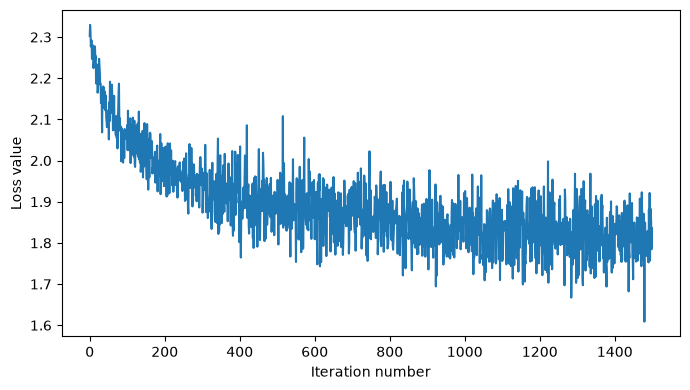

In [25]:
# Train with stochastic gradient descent.
import time

np.random.seed(1)
tic = time.time()
loss_hist = softmax.train(X_train, y_train, learning_rate=1e-7,
                         num_iters=1500, verbose=True)
toc = time.time()
print('That took {}s'.format(toc - tic))

plt.figure(figsize=(7, 4))
plt.plot(loss_hist)
plt.xlabel('Iteration number')
plt.ylabel('Loss value')
plt.tight_layout()
plt.show()

### Evaluate the performance of the trained softmax classifier on the validation data.

In [26]:
y_train_pred = softmax.predict(X_train)
print('training accuracy: %.4f' % np.mean(y_train == y_train_pred))
y_val_pred = softmax.predict(X_val)
print('validation accuracy: %.4f' % np.mean(y_val == y_val_pred))

training accuracy: 0.3816
validation accuracy: 0.3920


## Optimize the softmax classifier

In [27]:
np.finfo(float).eps

np.float64(2.220446049250313e-16)

learning rate 5.0e-08: training accuracy 0.3603, validation accuracy 0.3660


learning rate 1.0e-07: training accuracy 0.3816, validation accuracy 0.3920


learning rate 2.0e-07: training accuracy 0.3962, validation accuracy 0.4130


learning rate 5.0e-07: training accuracy 0.4131, validation accuracy 0.4140


learning rate 1.0e-06: training accuracy 0.4212, validation accuracy 0.4020


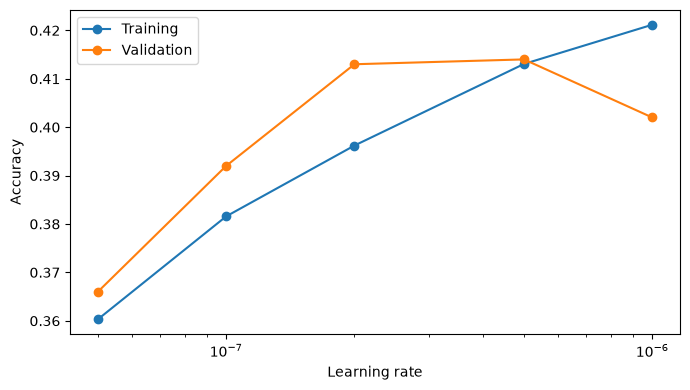

Best learning rate: 5.0e-07
Best validation accuracy: 0.4140
Test accuracy: 0.3840


In [28]:
learning_rates = [5e-8, 1e-7, 2e-7, 5e-7, 1e-6]
results = {}
best_val = -1
best_softmax = None
best_learning_rate = None

for learning_rate in learning_rates:
    # Use the same initialization and batch sequence for each learning rate.
    np.random.seed(1)
    model = Softmax(dims=[num_classes, num_features])
    np.random.seed(1)
    history = model.train(X_train, y_train, learning_rate=learning_rate,
                          num_iters=1500, batch_size=200)
    train_acc = np.mean(model.predict(X_train) == y_train)
    val_acc = np.mean(model.predict(X_val) == y_val)
    results[learning_rate] = (train_acc, val_acc)
    print('learning rate %.1e: training accuracy %.4f, validation accuracy %.4f'
          % (learning_rate, train_acc, val_acc))
    if val_acc > best_val:
        best_val = val_acc
        best_softmax = model
        best_learning_rate = learning_rate

plt.figure(figsize=(7, 4))
plt.semilogx(learning_rates, [results[lr][0] for lr in learning_rates], 'o-', label='Training')
plt.semilogx(learning_rates, [results[lr][1] for lr in learning_rates], 'o-', label='Validation')
plt.xlabel('Learning rate')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Evaluate the test set only after selecting the learning rate on validation data.
softmax_test_accuracy = np.mean(best_softmax.predict(X_test) == y_test)
print('Best learning rate: %.1e' % best_learning_rate)
print('Best validation accuracy: %.4f' % best_val)
print('Test accuracy: %.4f' % softmax_test_accuracy)

Among the tested rates, the best learning rate was $5.0\times10^{-7}$. Its validation accuracy was $41.40\%$ and its test accuracy was $38.40\%$. I selected the learning rate using validation accuracy and evaluated the selected model once on the test set.